# Analyzing AngioCAD Dataset Structure and Statistics

In [274]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import json
import cv2
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

# Set paths
DATA_DIR = Path('./data/raw')
PATIENT_DIR = Path("./data/raw/AngioCAD_Dataset")
FEATURES_FILE = DATA_DIR / 'AngioCAD_Features.xlsx'
LABELS_FILE = DATA_DIR / 'AngioCAD_Labels.xlsx'
OUTPUT_DIR = Path('./data/processed')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [275]:
print("ANGIOCAD DATASET ANALYSIS - IMAGE ONLY")

# Load data
df_features = pd.read_excel(FEATURES_FILE)
df_labels = pd.read_excel(LABELS_FILE)


# Features information
df_features.shape
df_features.info()


ANGIOCAD DATASET ANALYSIS - IMAGE ONLY
<class 'pandas.DataFrame'>
RangeIndex: 377 entries, 0 to 376
Data columns (total 60 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ID                     377 non-null    int64  
 1   Sex                    377 non-null    str    
 2   Age                    371 non-null    float64
 3   Length                 345 non-null    float64
 4   Weight                 346 non-null    float64
 5   BMI                    344 non-null    float64
 6   dominance              377 non-null    str    
 7   Right Coronary Series  377 non-null    str    
 8   Left Coronary Series   377 non-null    str    
 9   Diagnosis              377 non-null    str    
 10  DM                     377 non-null    int64  
 11  HTN                    377 non-null    int64  
 12  LVEF                   293 non-null    float64
 13  LVEF dysfunction       292 non-null    float64
 14  Hyperlipidemia         377 non

In [276]:
# Labels information
df_labels.shape
df_labels.info()

<class 'pandas.DataFrame'>
RangeIndex: 413 entries, 0 to 412
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   ID                     413 non-null    int64
 1   Right Coronary Series  413 non-null    str  
 2   Left Coronary Series   413 non-null    str  
 3   LM                     413 non-null    str  
 4   Prox LAD               413 non-null    str  
 5   Mid LAD                413 non-null    str  
 6   Dist LAD               413 non-null    str  
 7   1st dig                413 non-null    str  
 8   2nd dig                413 non-null    str  
 9   Prox LCX               413 non-null    str  
 10  Mid LCX                413 non-null    str  
 11  Dist LCX               413 non-null    str  
 12  OM                     413 non-null    str  
 13  Prox RCA               413 non-null    str  
 14  Mid RCA                413 non-null    str  
 15  Dist RCA               413 non-null    str  
 16  P

In [277]:
# merge dataframes
df = pd.merge(df_features, df_labels, on='ID', how='inner')

df.shape

print(df_labels.columns.tolist())

['ID', 'Right Coronary Series', 'Left Coronary Series', 'LM', 'Prox LAD', 'Mid LAD', 'Dist LAD', '1st dig', '2nd dig', 'Prox LCX', 'Mid LCX', 'Dist LCX', 'OM', 'Prox RCA', 'Mid RCA', 'Dist RCA', 'PDA', 'PLB']


In [278]:
# Basic information

print(f"\nTotal patients: {len(df_features)}")
print(f"Patients with labels: {len(df_labels)}")


# gender wise
if 'Sex' in df_features.columns:
    print("\nSex distribution:")
    sex_counts = df_features['Sex'].value_counts()
    for sex, count in sex_counts.items():
        print(f"  {sex}: {count} ({count/len(df_features)*100:.1f}%)")
        
# Age wise info
if 'Age' in df_features.columns:
    age_data = df_features['Age'].dropna()
    print(f"\nAge statistics:")
    print(f"  Mean: {age_data.mean():.1f} ± {age_data.std():.1f}")
    print(f"  Median: {age_data.median():.1f}")
    print(f"  Range: {age_data.min():.1f} - {age_data.max():.1f}")


Total patients: 377
Patients with labels: 413

Sex distribution:
  Male: 266 (70.6%)
  Female: 111 (29.4%)

Age statistics:
  Mean: 55.3 ± 10.9
  Median: 54.0
  Range: 21.0 - 89.0


In [279]:
# Diagnosis
print("\nDiagnosis distribution:")
if 'Diagnosis' in df_features.columns:
    diag_counts = df_features['Diagnosis'].value_counts()
    for diag, count in diag_counts.items():
        print(f"  {diag}: {count} ({count/len(df_features)*100:.1f}%)")


Diagnosis distribution:
  STEMI: 186 (49.3%)
  SA: 116 (30.8%)
  UA: 55 (14.6%)
  NSTEMI: 20 (5.3%)


In [280]:
# Risk factors
risk_factors = ['DM', 'HTN', 'Hyperlipidemia', 'Current Smoker', 'PVD', 'IHD', 'Stroke']
print("\nRisk factors prevalence:")
for factor in risk_factors:
    if factor in df_features.columns:
        count = df_features[factor].sum()
        print(f"  {factor}: {count} ({count/len(df_features)*100:.1f}%)")



Risk factors prevalence:
  DM: 94 (24.9%)
  HTN: 123 (32.6%)
  Hyperlipidemia: 71 (18.8%)
  Current Smoker: 106.0 (28.1%)
  PVD: 90 (23.9%)
  IHD: 59 (15.6%)
  Stroke: 5 (1.3%)


In [281]:
# Stenosis
print("\nStenosis distribution:")

STENOSIS_COLS = ['LM', 'Prox LAD', 'Mid LAD', 'Dist LAD', '1st dig', '2nd dig',
                 'Prox LCX', 'Mid LCX', 'Dist LCX', 'OM', 'Prox RCA', 
                 'Mid RCA', 'Dist RCA', 'PDA', 'PLB']

def parse_stenosis(val):
    """Parse stenosis percentage from string values"""
    if pd.isna(val):
        return np.nan
    if val == 'NL':
        return 0
    if isinstance(val, (int, float)):
        return val
    if isinstance(val, str):
        if '-' in val:
            parts = val.split('-')
            try:
                return (int(parts[0]) + int(parts[1])) / 2
            except:
                return np.nan
        if val.isdigit():
            return int(val)
    return np.nan

stenosis_data = {}
for col in STENOSIS_COLS:
    if col in df_labels.columns:
        stenosis_data[col] = df_labels[col].apply(parse_stenosis).dropna()

print(f"\nNumber of vessels with data: {len(stenosis_data)}")



Stenosis distribution:

Number of vessels with data: 15


In [282]:
stats_list = []
for col, vals in stenosis_data.items():
    if len(vals) > 0:
        stats_list.append({
            'Vessel': col,
            'Mean': vals.mean(),
            'Median': vals.median(),
            'Std': vals.std(),
            'Min': vals.min(),
            'Max': vals.max(),
            'N': len(vals),
            'CAD_Present': (vals >= 50).sum(),
            'CAD_Pct': (vals >= 50).sum() / len(vals) * 100
        })

stats_df = pd.DataFrame(stats_list)
print("\nStenosis statistics per vessel:")
print(stats_df.round(2).to_string(index=False))


Stenosis statistics per vessel:
  Vessel  Mean  Median   Std  Min   Max   N  CAD_Present  CAD_Pct
      LM  2.02     0.0  9.11  0.0  83.0 413            5     1.21
Prox LAD 23.08     0.0 35.26  0.0 100.0 413           89    21.55
 Mid LAD 48.34    63.0 41.93  0.0 100.0 413          207    50.12
Dist LAD  6.02     0.0 21.22  0.0 100.0 413           28     6.78
 1st dig 23.41     0.0 36.38  0.0 100.0 413          100    24.21
 2nd dig  7.64     0.0 23.45  0.0 100.0 413           34     8.23
Prox LCX 12.47     0.0 26.22  0.0 100.0 413           46    11.14
 Mid LCX 11.83     0.0 27.64  0.0 100.0 413           45    10.90
Dist LCX  4.77     0.0 19.55  0.0 100.0 413           19     4.60
      OM 24.05     0.0 36.29  0.0 100.0 413          101    24.46
Prox RCA 22.20     0.0 32.74  0.0 100.0 413           76    18.40
 Mid RCA 24.43     0.0 35.67  0.0 100.0 413           94    22.76
Dist RCA 10.54     0.0 25.88  0.0 100.0 413           40     9.69
     PDA  6.80     0.0 21.67  0.0 100.0 413

In [283]:
# CAD CLASSIFICATION

print("\n" + "=" * 60)
print("CAD CLASSIFICATION")
print("=" * 60)

# Maximum stenosis for each patient
df_labels["max_stenosis"] = 0.0

for col in STENOSIS_COLS:
    if col in df_labels.columns:
        values = df_labels[col].apply(parse_stenosis).fillna(0)
        df_labels["max_stenosis"] = np.maximum(df_labels["max_stenosis"], values)

# Binary CAD label (>=50%)
df_labels["has_cad"] = (df_labels["max_stenosis"] >= 50).astype(int)

# Severity classification
def get_severity(max_stenosis):
    if max_stenosis == 0:
        return "Normal"
    elif max_stenosis < 30:
        return "Mild"
    elif max_stenosis < 50:
        return "Mild-Moderate"
    elif max_stenosis < 70:
        return "Moderate"
    else:
        return "Severe"

df_labels["severity"] = df_labels["max_stenosis"].apply(get_severity)

# Number of diseased vessels (>=50%)
df_labels["num_diseased_vessels"] = 0

for col in STENOSIS_COLS:
    if col in df_labels.columns:
        df_labels["num_diseased_vessels"] += (
            df_labels[col]
            .apply(parse_stenosis)
            .fillna(0)
            .ge(50)
            .astype(int)
        )

# Print summary
cad_counts = df_labels["has_cad"].value_counts()

print("\nBinary CAD Distribution:")
print(f"CAD Present : {cad_counts.get(1,0)} ({cad_counts.get(1,0)/len(df_labels)*100:.1f}%)")
print(f"CAD Absent  : {cad_counts.get(0,0)} ({cad_counts.get(0,0)/len(df_labels)*100:.1f}%)")

print("\nSeverity Distribution:")
print(df_labels["severity"].value_counts())

print("\nNumber of Diseased Vessels:")
print(df_labels["num_diseased_vessels"].value_counts().sort_index())


CAD CLASSIFICATION

Binary CAD Distribution:
CAD Present : 324 (78.5%)
CAD Absent  : 89 (21.5%)

Severity Distribution:
severity
Severe           319
Normal            53
Mild              24
Mild-Moderate     12
Moderate           5
Name: count, dtype: int64

Number of Diseased Vessels:
num_diseased_vessels
0     89
1     91
2     75
3     54
4     44
5     30
6     15
7      8
8      5
9      1
10     1
Name: count, dtype: int64


In [284]:
# Severity classification
def get_max_stenosis(row):
    max_val = 0
    for col in STENOSIS_COLS:
        if col in df_labels.columns:
            val = parse_stenosis(row[col])
            if pd.notna(val) and val > max_val:
                max_val = val
    return max_val

def get_severity_class(max_stenosis):
    if max_stenosis == 0:
        return 'Normal'
    elif max_stenosis < 30:
        return 'Mild'
    elif max_stenosis < 50:
        return 'Mild-Moderate'
    elif max_stenosis < 70:
        return 'Moderate'
    else:
        return 'Severe'

df_labels['max_stenosis'] = df_labels.apply(get_max_stenosis, axis=1)
df_labels['severity'] = df_labels['max_stenosis'].apply(get_severity_class)

severity_counts = df_labels['severity'].value_counts()
print("\nSeverity distribution:")
severity_order = ['Normal', 'Mild', 'Mild-Moderate', 'Moderate', 'Severe']
for severity in severity_order:
    count = severity_counts.get(severity, 0)
    print(f"  {severity}: {count} ({count/len(df_labels)*100:.1f}%)")

# Number of diseased vessels
def count_diseased_vessels(row, threshold=50):
    count = 0
    for col in STENOSIS_COLS:
        if col in df_labels.columns:
            val = parse_stenosis(row[col])
            if pd.notna(val) and val >= threshold:
                count += 1
    return count

df_labels['num_diseased_vessels'] = df_labels.apply(count_diseased_vessels, axis=1)
print(f"\nNumber of diseased vessels (≥50%):")
print(df_labels['num_diseased_vessels'].value_counts().sort_index().to_string())


Severity distribution:
  Normal: 53 (12.8%)
  Mild: 24 (5.8%)
  Mild-Moderate: 12 (2.9%)
  Moderate: 5 (1.2%)
  Severe: 319 (77.2%)

Number of diseased vessels (≥50%):
num_diseased_vessels
0     89
1     91
2     75
3     54
4     44
5     30
6     15
7      8
8      5
9      1
10     1


In [285]:
df = pd.merge(df_features, df_labels, on="ID", how="inner")

In [286]:

# Image information
print("\nImage information")
patient_folders = sorted([p for p in PATIENT_DIR.iterdir() if p.is_dir()])

total_images = 0
patient_stats = {}


for patient in patient_folders:

    patient_id = patient.name

    series_folders = sorted([s for s in patient.iterdir() if s.is_dir()])

    patient_total = 0

    print(f"\nPatient {patient_id}")

    for series in series_folders:

        images = []

        images.extend(series.glob("*.jpg"))
        images.extend(series.glob("*.png"))
        images.extend(series.glob("*.jpeg"))

        n = len(images)

        patient_total += n

        print(f"   Series {series.name}: {n} frames")

    patient_stats[patient_id] = patient_total
    total_images += patient_total

print("\n" + "="*60)
print("SUMMARY")
print("="*60)

print(f"Patients           : {len(patient_folders)}")
print(f"Total Images       : {total_images}")
print(f"Average / Patient  : {total_images/len(patient_folders):.2f}")
print(f"Minimum Images     : {min(patient_stats.values())}")
print(f"Maximum Images     : {max(patient_stats.values())}")


Image information

Patient 1
   Series 1: 72 frames
   Series 2: 94 frames
   Series 3: 70 frames
   Series 4: 49 frames
   Series 5: 72 frames
   Series 6: 61 frames
   Series 7: 61 frames
   Series 8: 51 frames
   Series 9: 48 frames

Patient 10
   Series 1: 42 frames
   Series 2: 41 frames
   Series 3: 38 frames
   Series 4: 51 frames
   Series 5: 58 frames
   Series 6: 40 frames
   Series 7: 32 frames
   Series 8: 54 frames

Patient 100
   Series 1: 53 frames
   Series 2: 33 frames
   Series 3: 50 frames
   Series 4: 47 frames
   Series 5: 39 frames
   Series 6: 52 frames
   Series 7: 47 frames
   Series 8: 38 frames
   Series 9: 40 frames

Patient 101
   Series 1: 31 frames
   Series 2: 32 frames
   Series 3: 33 frames
   Series 4: 35 frames
   Series 5: 41 frames
   Series 6: 26 frames

Patient 102
   Series 1: 37 frames
   Series 2: 28 frames
   Series 3: 32 frames
   Series 4: 37 frames
   Series 5: 28 frames
   Series 6: 32 frames

Patient 103
   Series 1: 21 frames
   Series

In [287]:
# Images per patient

images_per_patient = {}
images_per_series = {}

total_images = 0

patient_folders = sorted(
    [d for d in PATIENT_DIR.iterdir() if d.is_dir()],
    key=lambda x: int(x.name)
)

for patient in patient_folders:

    patient_total = 0

    series_folders = sorted(
        [d for d in patient.iterdir() if d.is_dir()],
        key=lambda x: int(x.name)
    )

    for series in series_folders:

        image_count = (
            len(list(series.glob("*.jpg"))) +
            len(list(series.glob("*.png"))) +
            len(list(series.glob("*.jpeg")))
        )

        patient_total += image_count
        total_images += image_count

        images_per_series[f"{patient.name}-{series.name}"] = image_count

    images_per_patient[patient.name] = patient_total

print("Patients :", len(images_per_patient))
print("Images   :", total_images)

Patients : 413
Images   : 121566


In [288]:
# RIGHT / LEFT CORONARY FRAME STATISTICS

from pathlib import Path
import pandas as pd

right_total = 0
left_total = 0

right_patient = {}
left_patient = {}

RIGHT_COL = "Right Coronary Series_y"
LEFT_COL = "Left Coronary Series_y"

for _, row in df.iterrows():

    patient_id = str(int(row["ID"]))
    patient_path = PATIENT_DIR / patient_id

    if not patient_path.exists():
        continue

    patient_right = 0
    patient_left = 0

    # Right Coronary

    if pd.notna(row[RIGHT_COL]):

        for s in str(row[RIGHT_COL]).split("-"):

            s = s.strip()

            if not s:
                continue

            series_path = patient_path / s

            if series_path.exists():

                n = (
                    len(list(series_path.glob("*.jpg"))) +
                    len(list(series_path.glob("*.png"))) +
                    len(list(series_path.glob("*.jpeg")))
                )

                patient_right += n
                right_total += n

    #  Left Coronary

    if pd.notna(row[LEFT_COL]):

        for s in str(row[LEFT_COL]).split("-"):

            s = s.strip()

            if not s:
                continue

            series_path = patient_path / s

            if series_path.exists():

                n = (
                    len(list(series_path.glob("*.jpg"))) +
                    len(list(series_path.glob("*.png"))) +
                    len(list(series_path.glob("*.jpeg")))
                )

                patient_left += n
                left_total += n

    right_patient[patient_id] = patient_right
    left_patient[patient_id] = patient_left

print("=" * 60)
print("RIGHT / LEFT CORONARY FRAME STATISTICS")
print("=" * 60)

print(f"Right Coronary Frames : {right_total:,}")
print(f"Left Coronary Frames  : {left_total:,}")
print(f"Total Frames          : {right_total + left_total:,}")

print(f"\nAverage Right Frames / Patient : {right_total / len(right_patient):.2f}")
print(f"Average Left Frames  / Patient : {left_total / len(left_patient):.2f}")

RIGHT / LEFT CORONARY FRAME STATISTICS
Right Coronary Frames : 29,011
Left Coronary Frames  : 31,857
Total Frames          : 60,868

Average Right Frames / Patient : 76.95
Average Left Frames  / Patient : 84.50



CORRELATION ANALYSIS

Correlation Matrix
                  Age    BMI     DM    HTN  Hyperlipidemia  Current Smoker  \
Age             1.000 -0.099  0.079  0.059          -0.022          -0.108   
BMI            -0.099  1.000  0.063 -0.023           0.013           0.023   
DM              0.079  0.063  1.000  0.221           0.193           0.009   
HTN             0.059 -0.023  0.221  1.000           0.133          -0.034   
Hyperlipidemia -0.022  0.013  0.193  0.133           1.000           0.100   
Current Smoker -0.108  0.023  0.009 -0.034           0.100           1.000   
has_cad         0.207 -0.103  0.046 -0.014           0.113           0.238   

                has_cad  
Age               0.207  
BMI              -0.103  
DM                0.046  
HTN              -0.014  
Hyperlipidemia    0.113  
Current Smoker    0.238  
has_cad           1.000  

Correlation with CAD (≥50% stenosis)
---------------------------------------------
Current Smoker       :   0.238
Age       

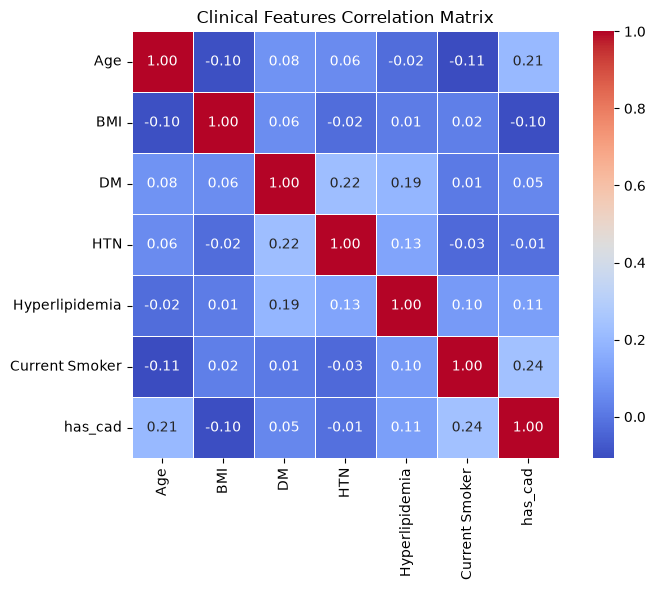

In [289]:
# CORRELATION ANALYSIS

print("\n" + "=" * 60)
print("CORRELATION ANALYSIS")
print("=" * 60)

clinical_vars = [
    "Age",
    "BMI",
    "DM",
    "HTN",
    "Hyperlipidemia",
    "Current Smoker"
]

# Keep only available columns
available_vars = [col for col in clinical_vars if col in df.columns]

# Select required columns
corr_data = df[available_vars + ["has_cad"]].copy()

# Convert to numeric
corr_data = corr_data.apply(pd.to_numeric, errors="coerce")

# Remove rows with missing values
corr_data = corr_data.dropna()

if len(corr_data) < 2:
    print("Not enough valid samples for correlation analysis.")

elif corr_data["has_cad"].nunique() < 2:
    print("Correlation cannot be computed because 'has_cad' has only one class.")

else:

    # Pearson correlation matrix
    corr_matrix = corr_data.corr(method="pearson")

    print("\nCorrelation Matrix")
    print(corr_matrix.round(3))

    print("\nCorrelation with CAD (≥50% stenosis)")
    print("-" * 45)

    cad_corr = (
        corr_matrix["has_cad"]
        .drop("has_cad")
        .sort_values(ascending=False)
    )

    for feature, value in cad_corr.items():
        print(f"{feature:<20} : {value:7.3f}")

    # Optional heatmap
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        corr_matrix,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        square=True,
        linewidths=0.5
    )
    plt.title("Clinical Features Correlation Matrix")
    plt.tight_layout()
    plt.show()

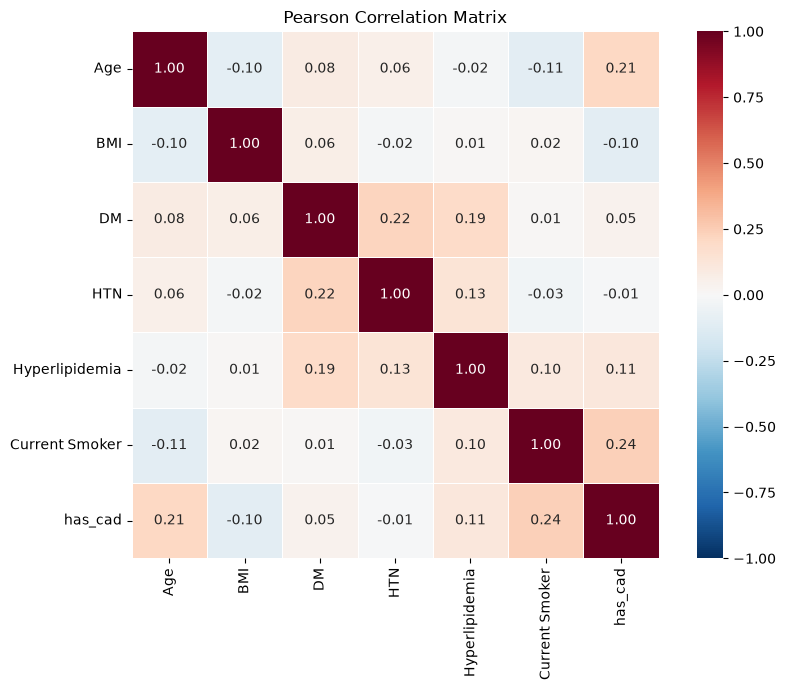

In [290]:
plt.figure(figsize=(9,7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=.5,
    square=True,
    fmt=".2f"
)

plt.title("Pearson Correlation Matrix")
plt.tight_layout()
plt.show()

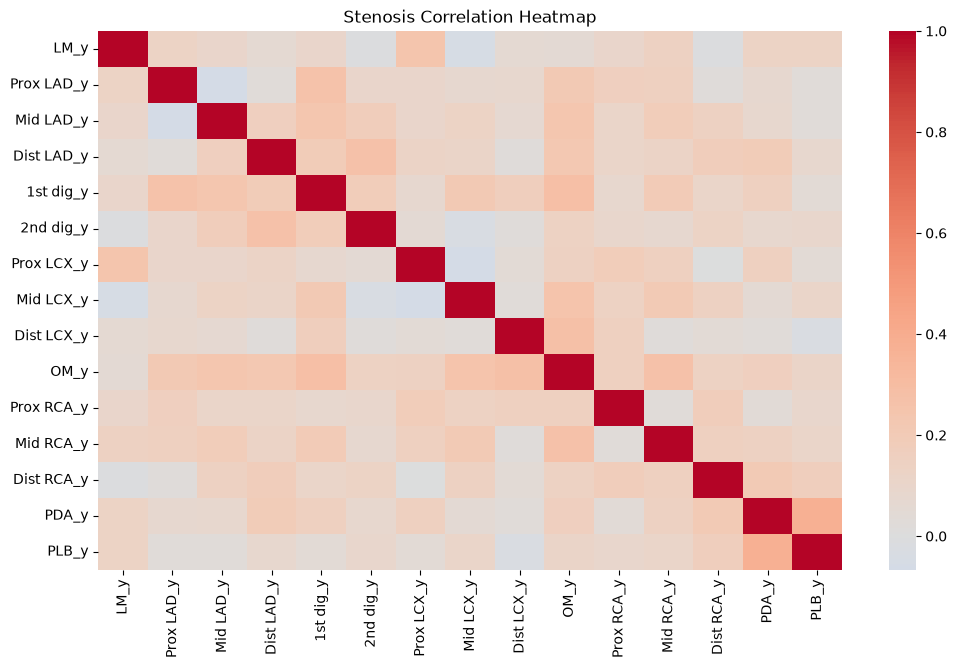

In [291]:
# Stenosis heatmap
stenosis_cols = [
    "LM_y","Prox LAD_y","Mid LAD_y","Dist LAD_y",
    "1st dig_y","2nd dig_y",
    "Prox LCX_y","Mid LCX_y","Dist LCX_y",
    "OM_y",
    "Prox RCA_y","Mid RCA_y","Dist RCA_y",
    "PDA_y","PLB_y"
]

heatmap_df = df[stenosis_cols].copy()

for col in stenosis_cols:
    heatmap_df[col] = heatmap_df[col].apply(parse_stenosis)

plt.figure(figsize=(12,7))

sns.heatmap(
    heatmap_df.corr(),
    cmap="coolwarm",
    center=0
)

plt.title("Stenosis Correlation Heatmap")

plt.show()

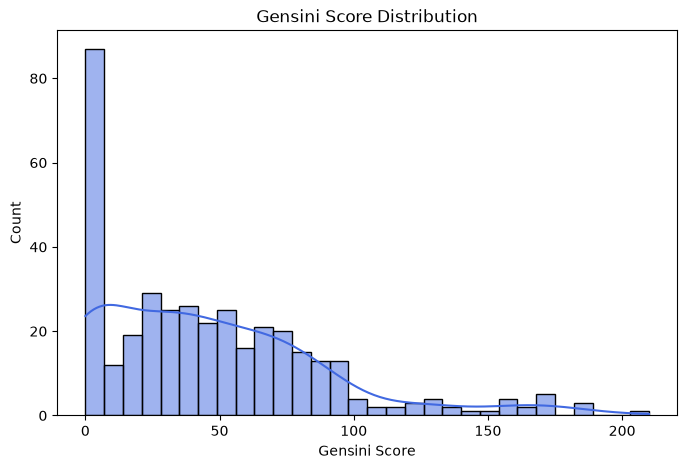

In [292]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["Gensini Score"],
    bins=30,
    kde=True,
    color="royalblue"
)

plt.title("Gensini Score Distribution")
plt.xlabel("Gensini Score")

plt.show()

In [293]:
#  CHI-SQUARE TEST

from scipy.stats import chi2_contingency

print("\n" + "=" * 60)
print("CHI-SQUARE TEST")
print("=" * 60)

categorical_features = [
    "Sex",
    "Diagnosis",
    "DM",
    "HTN",
    "Hyperlipidemia",
    "Current Smoker"
]

results = []

for feature in categorical_features:

    if feature not in df.columns:
        continue

    contingency = pd.crosstab(df[feature], df["has_cad"])

    chi2, p, dof, expected = chi2_contingency(contingency)

    results.append({
        "Feature": feature,
        "Chi-Square": round(chi2,3),
        "Degrees of Freedom": dof,
        "P-value": round(p,5),
        "Significant": "Yes" if p < 0.05 else "No"
    })

chi_df = pd.DataFrame(results)

print(chi_df)

# Save
chi_df.to_csv(
    OUTPUT_DIR / "chi_square_results.csv",
    index=False
)


CHI-SQUARE TEST
          Feature  Chi-Square  Degrees of Freedom  P-value Significant
0             Sex      41.634                   1  0.00000         Yes
1       Diagnosis      96.540                   3  0.00000         Yes
2              DM       0.413                   1  0.52035          No
3             HTN       0.005                   1  0.94093          No
4  Hyperlipidemia       4.262                   1  0.03898         Yes
5  Current Smoker      16.692                   1  0.00004         Yes


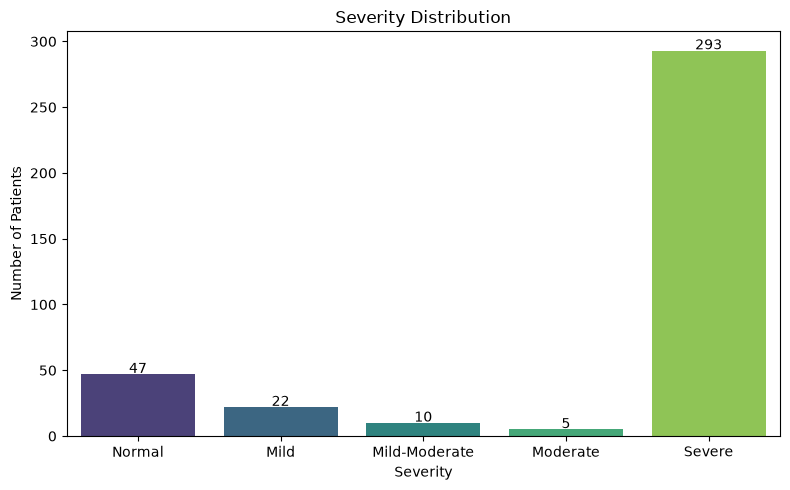

In [294]:
# Severity Distribution

plt.figure(figsize=(8,5))

severity_order = [
    "Normal",
    "Mild",
    "Mild-Moderate",
    "Moderate",
    "Severe"
]

severity_counts = (
    df["severity"]
    .value_counts()
    .reindex(severity_order)
)

sns.barplot(
    x=severity_counts.index,
    y=severity_counts.values,
    palette="viridis"
)

plt.title("Severity Distribution")
plt.xlabel("Severity")
plt.ylabel("Number of Patients")

for i,v in enumerate(severity_counts.values):
    plt.text(i,v+1,str(v),ha="center")

plt.tight_layout()
plt.show()

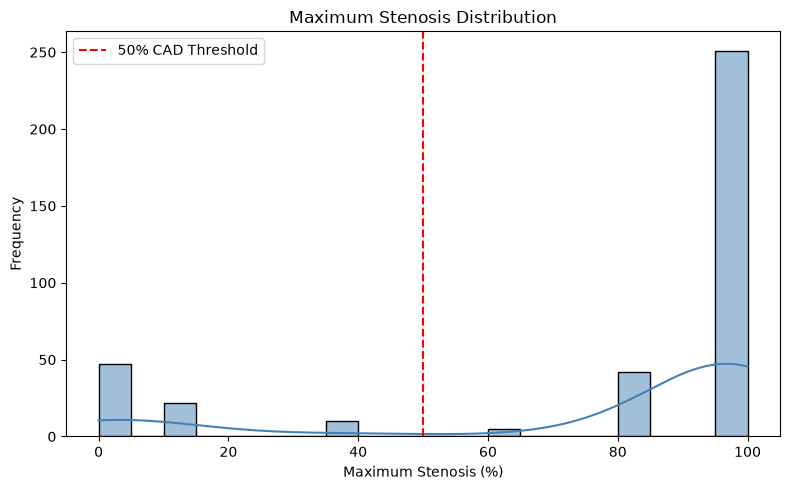

In [295]:
# Maximum Stenosis Distribution

plt.figure(figsize=(8,5))

sns.histplot(
    df["max_stenosis"],
    bins=20,
    kde=True,
    color="steelblue"
)

plt.axvline(
    50,
    color="red",
    linestyle="--",
    label="50% CAD Threshold"
)

plt.title("Maximum Stenosis Distribution")
plt.xlabel("Maximum Stenosis (%)")
plt.ylabel("Frequency")
plt.legend()

plt.tight_layout()
plt.show()

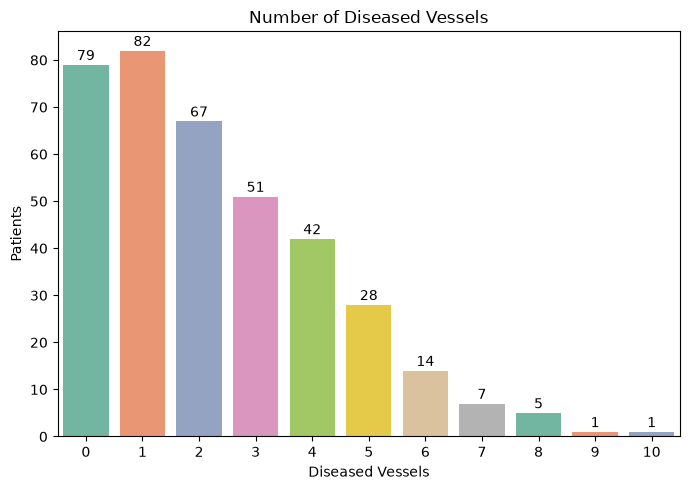

In [296]:
# Number of Diseased Vessels

plt.figure(figsize=(7,5))

vessel_counts = (
    df["num_diseased_vessels"]
    .value_counts()
    .sort_index()
)

sns.barplot(
    x=vessel_counts.index,
    y=vessel_counts.values,
    palette="Set2"
)

plt.title("Number of Diseased Vessels")
plt.xlabel("Diseased Vessels")
plt.ylabel("Patients")

for i,v in enumerate(vessel_counts.values):
    plt.text(i,v+1,str(v),ha="center")

plt.tight_layout()
plt.show()

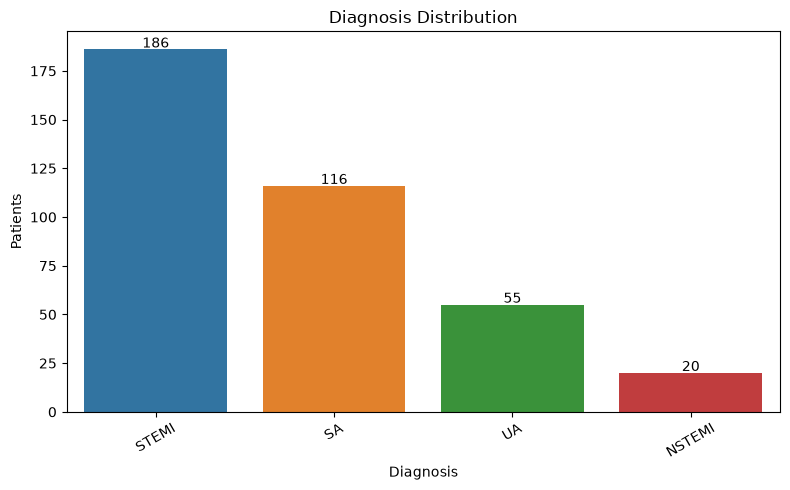

In [297]:
# Diagnosis Distribution

if "Diagnosis" in df.columns:

    plt.figure(figsize=(8,5))

    diagnosis = df["Diagnosis"].value_counts()

    sns.barplot(
        x=diagnosis.index,
        y=diagnosis.values,
        palette="tab10"
    )

    plt.title("Diagnosis Distribution")
    plt.xlabel("Diagnosis")
    plt.ylabel("Patients")

    plt.xticks(rotation=30)

    for i,v in enumerate(diagnosis.values):
        plt.text(i,v+1,str(v),ha="center")

    plt.tight_layout()
    plt.show()

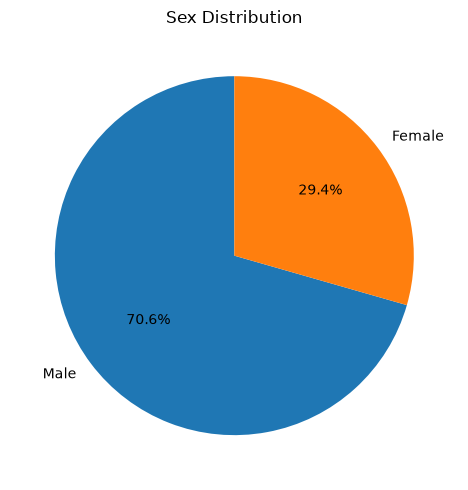

In [298]:
# ============================================================================
# Sex Distribution
# ============================================================================

if "Sex" in df.columns:

    plt.figure(figsize=(5,5))

    sex = df["Sex"].value_counts()

    plt.pie(
        sex.values,
        labels=sex.index,
        autopct="%1.1f%%",
        startangle=90
    )

    plt.title("Sex Distribution")
    plt.tight_layout()
    plt.show()

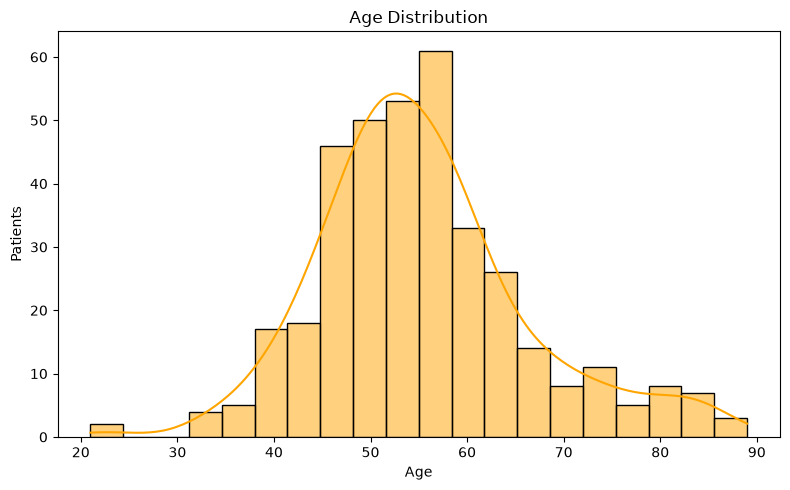

In [299]:
# ============================================================================
# Age Distribution
# ============================================================================

plt.figure(figsize=(8,5))

sns.histplot(
    df["Age"],
    bins=20,
    kde=True,
    color="orange"
)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Patients")

plt.tight_layout()
plt.show()

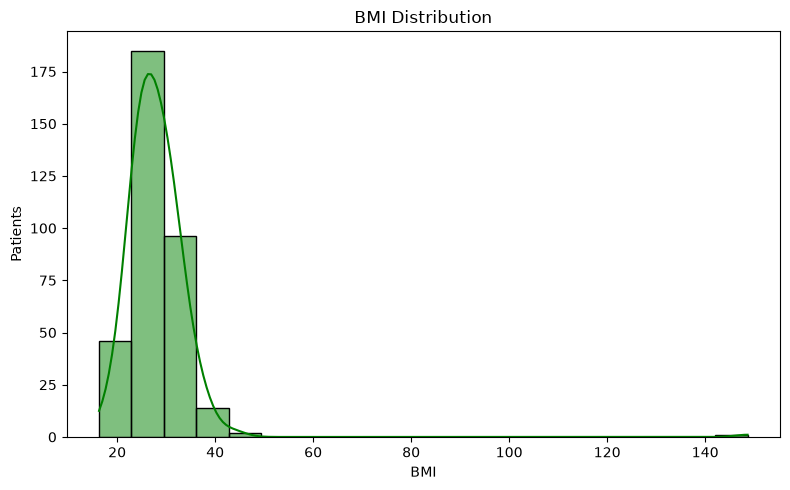

In [300]:
# ============================================================================
# BMI Distribution
# ============================================================================

if "BMI" in df.columns:

    plt.figure(figsize=(8,5))

    sns.histplot(
        df["BMI"],
        bins=20,
        kde=True,
        color="green"
    )

    plt.title("BMI Distribution")
    plt.xlabel("BMI")
    plt.ylabel("Patients")

    plt.tight_layout()
    plt.show()

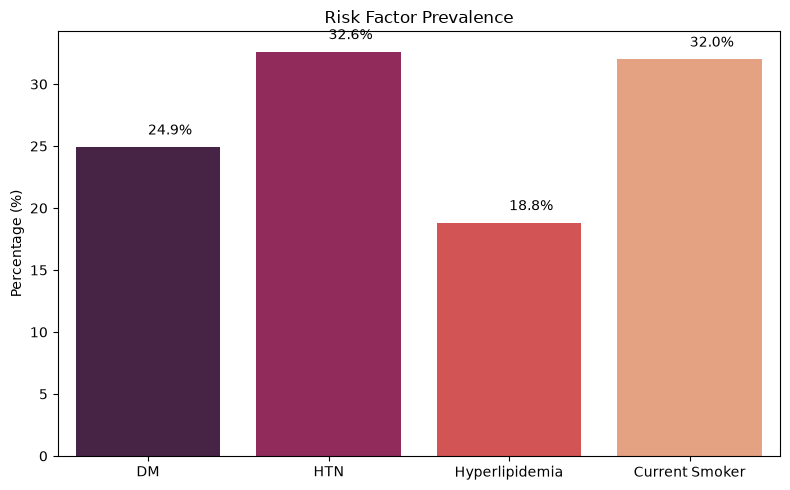

In [301]:
# ============================================================================
# Risk Factor Distribution
# ============================================================================

risk_cols = [
    "DM",
    "HTN",
    "Hyperlipidemia",
    "Current Smoker"
]

risk_cols = [c for c in risk_cols if c in df.columns]

risk_percent = {
    c: df[c].mean()*100
    for c in risk_cols
}

plt.figure(figsize=(8,5))

sns.barplot(
    x=list(risk_percent.keys()),
    y=list(risk_percent.values()),
    palette="rocket"
)

plt.ylabel("Percentage (%)")
plt.title("Risk Factor Prevalence")

for i,v in enumerate(risk_percent.values()):
    plt.text(i,v+1,f"{v:.1f}%")

plt.tight_layout()
plt.show()

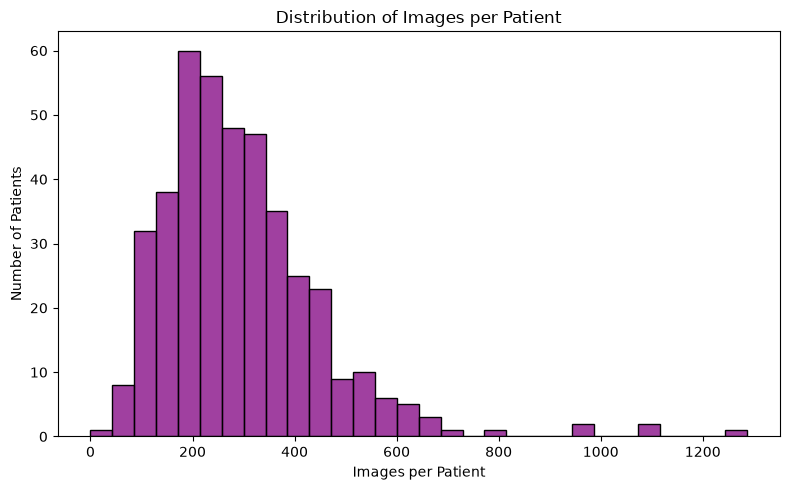

In [302]:
# image per patient
plt.figure(figsize=(8,5))

sns.histplot(
    list(images_per_patient.values()),
    bins=30,
    color="purple",
    edgecolor="black"
)

plt.xlabel("Images per Patient")
plt.ylabel("Number of Patients")
plt.title("Distribution of Images per Patient")

plt.tight_layout()
plt.show()

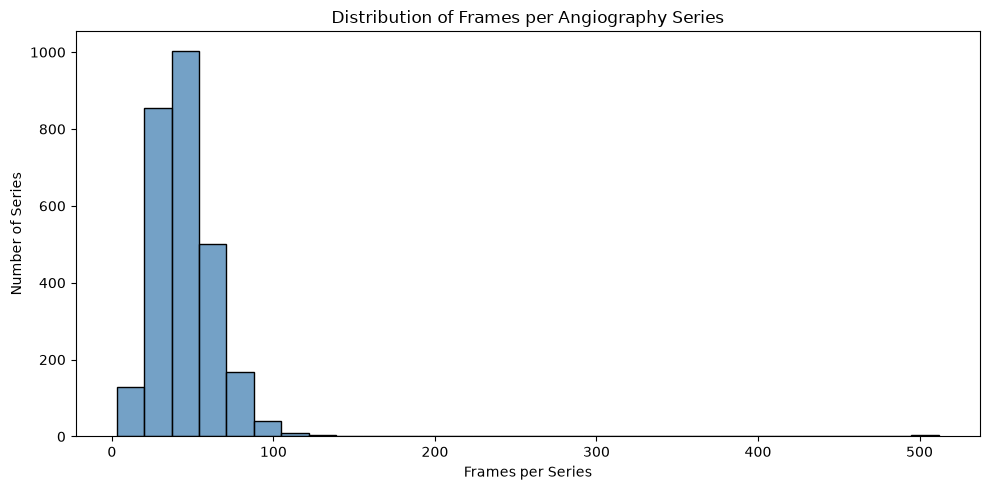

In [303]:
# Right left coronary series
plt.figure(figsize=(10,5))

series_counts = pd.Series(images_per_series)

sns.histplot(
    series_counts,
    bins=30,
    color="steelblue",
    edgecolor="black"
)

plt.xlabel("Frames per Series")
plt.ylabel("Number of Series")
plt.title("Distribution of Frames per Angiography Series")

plt.tight_layout()
plt.show()

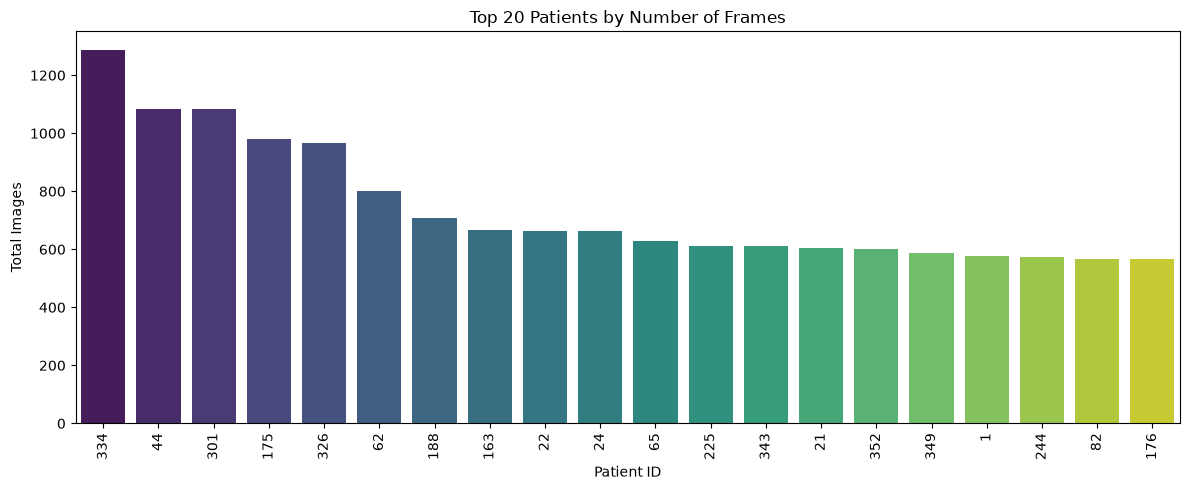

In [304]:
# Top 20 patients 
patient_series = pd.Series(images_per_patient).sort_values(ascending=False)

plt.figure(figsize=(12,5))

sns.barplot(
    x=patient_series.head(20).index,
    y=patient_series.head(20).values,
    palette="viridis"
)

plt.xticks(rotation=90)

plt.xlabel("Patient ID")
plt.ylabel("Total Images")
plt.title("Top 20 Patients by Number of Frames")

plt.tight_layout()
plt.show()

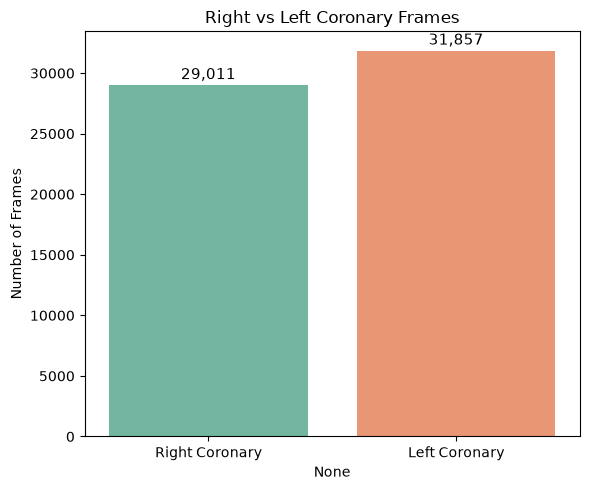

In [305]:
# Right vs left coronary frames
plt.figure(figsize=(6,5))

frame_counts = pd.Series({
    "Right Coronary": right_total,
    "Left Coronary": left_total
})

sns.barplot(
    x=frame_counts.index,
    y=frame_counts.values,
    palette="Set2"
)

plt.title("Right vs Left Coronary Frames")
plt.ylabel("Number of Frames")

for i, v in enumerate(frame_counts.values):
    plt.text(i, v + 500, f"{v:,}", ha="center", fontsize=11)

plt.tight_layout()
plt.show()

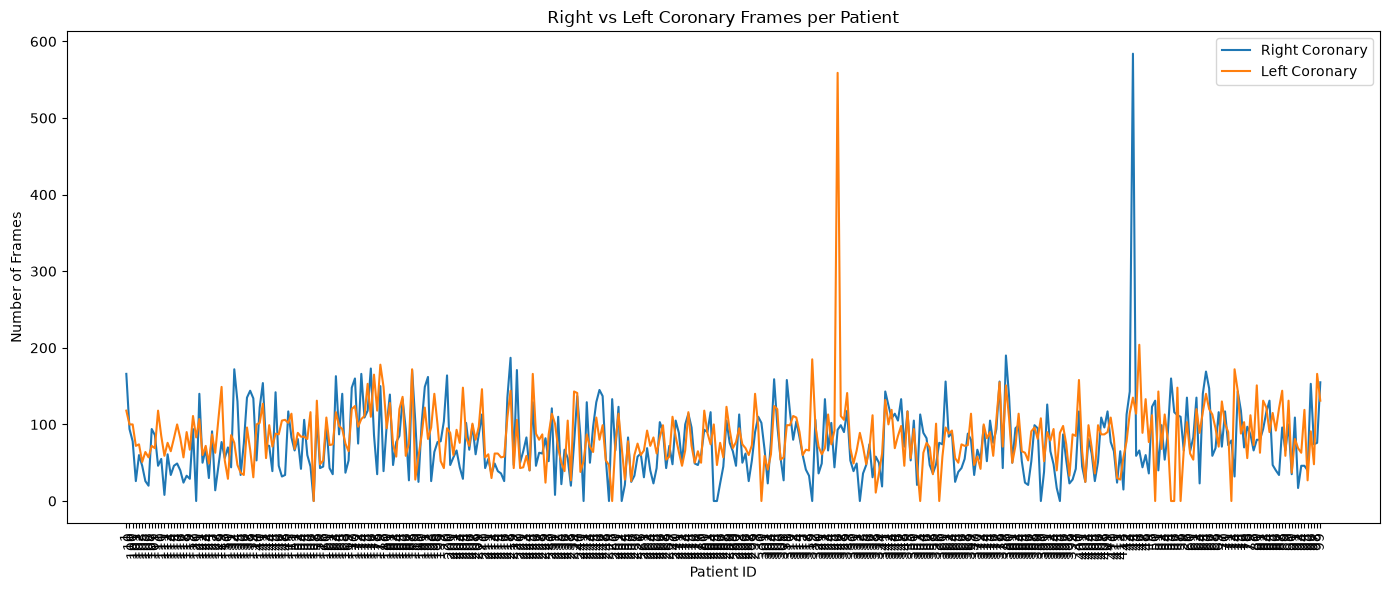

In [306]:
# Right vs left coronary per patient
patient_df = pd.DataFrame({
    "Patient": list(right_patient.keys()),
    "Right": list(right_patient.values()),
    "Left": list(left_patient.values())
})

patient_df = patient_df.sort_values("Patient")

plt.figure(figsize=(14,6))

plt.plot(patient_df["Patient"], patient_df["Right"], label="Right Coronary")
plt.plot(patient_df["Patient"], patient_df["Left"], label="Left Coronary")

plt.xticks(rotation=90)

plt.xlabel("Patient ID")
plt.ylabel("Number of Frames")
plt.title("Right vs Left Coronary Frames per Patient")

plt.legend()

plt.tight_layout()
plt.show()

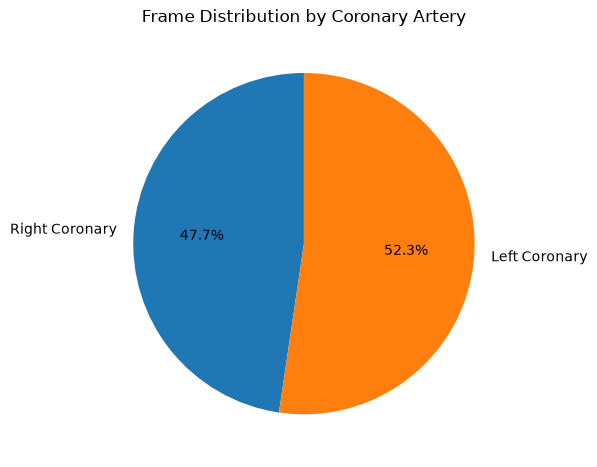

In [307]:
plt.figure(figsize=(6,6))

plt.pie(
    [right_total, left_total],
    labels=["Right Coronary", "Left Coronary"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Frame Distribution by Coronary Artery")

plt.tight_layout()
plt.show()